   Dien_tich     Gia_ban
0         30  289.901425
1         40  295.852071
2         50  344.430656
3         60  395.690896
4         70  367.975399
5         80  392.975891
6         90  472.376384
7        100  473.023042
8        120  485.915768
9        150  591.276801
Hệ số hồi quy: 2.4710972129889757
Hệ số chặn: 215.7251535248336
Giá dự đoán: 401.05744449900675


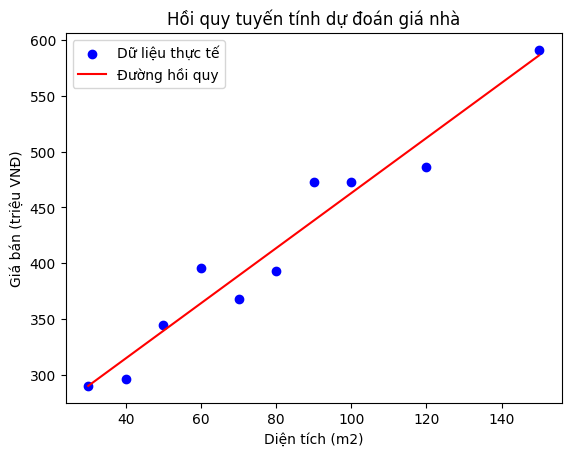

In [7]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split
np.random.seed(42)
dien_tich=np.array([30,40,50,60,70,80,90,100,120,150])
giaban=2.5*dien_tich+200+np.random.normal(0,30,10)
df=pd.DataFrame({"Dien_tich":dien_tich,"Gia_ban":giaban})
print(df)
x=df[["Dien_tich"]]
y=df["Gia_ban"]
model=LinearRegression()
model.fit(x,y)
du_doan=model.predict(pd.DataFrame({"Dien_tich":[75]}))
print("Hệ số hồi quy:",model.coef_[0])
print("Hệ số chặn:",model.intercept_)
print("Giá dự đoán:",du_doan[0])
plt.scatter(dien_tich, giaban, color="blue", label="Dữ liệu thực tế")
plt.plot(dien_tich, model.predict(x), color="red", label="Đường hồi quy")
plt.xlabel("Diện tích (m2)")
plt.ylabel("Giá bán (triệu VNĐ)")
plt.title("Hồi quy tuyến tính dự đoán giá nhà")
plt.legend()
plt.show()

5 dòng dữ liệu đầu tiên:
         BMI  Mac_benh
0  24.363503         0
1  38.767858         1
2  33.299849         1
3  29.966462         0
4  18.900466         0

Số lượng từng nhãn:
Mac_benh
1    515
0    485
Name: count, dtype: int64

Độ chính xác: 0.815

Báo cáo phân loại:
              precision    recall  f1-score   support

           0       0.83      0.78      0.80        97
           1       0.81      0.84      0.82       103

    accuracy                           0.81       200
   macro avg       0.82      0.81      0.81       200
weighted avg       0.82      0.81      0.81       200



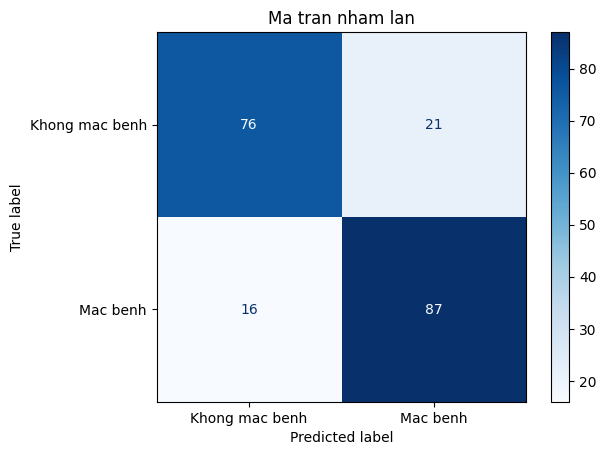

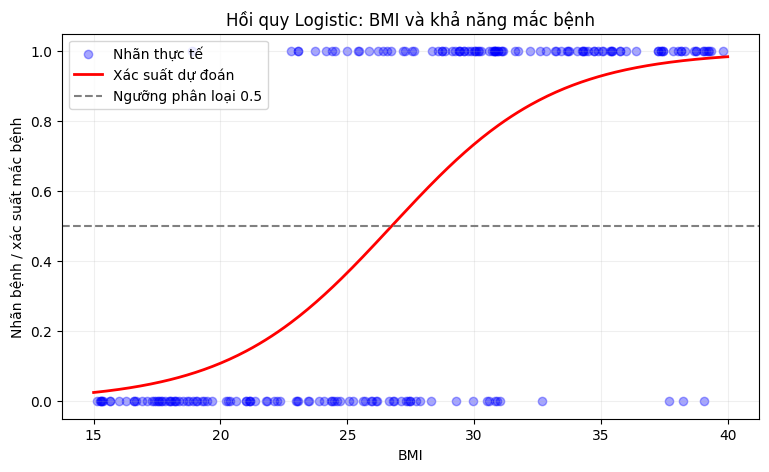


Kết quả dự đoán:
   BMI  Xac_suat_mac_benh  Nhan_du_doan
0   20              0.109             0
1   25              0.367             0
2   30              0.734             1
3   35              0.929             1


In [19]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    ConfusionMatrixDisplay
)


np.random.seed(42)

n = 1000
bmi = np.random.uniform(15, 40, n)


xac_suat = 1 / (1 + np.exp(-(bmi - 27) / 3))


mac_benh = np.random.binomial(1, xac_suat)

df = pd.DataFrame({
    "BMI": bmi,
    "Mac_benh": mac_benh
})

print("5 dòng dữ liệu đầu tiên:")
print(df.head())

print("\nSố lượng từng nhãn:")
print(df["Mac_benh"].value_counts())

X = df[["BMI"]]
y = df["Mac_benh"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
model = LogisticRegression()
model.fit(X_train, y_train)


y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("\nĐộ chính xác:", accuracy_score(y_test, y_pred))
print("\nBáo cáo phân loại:")
print(classification_report(y_test, y_pred, zero_division=0))


cm = confusion_matrix(y_test, y_pred, labels=[0, 1])

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Khong mac benh", "Mac benh"]
)
disp.plot(cmap="Blues")
plt.title("Ma tran nham lan")
plt.show()

bmi_range = np.linspace(15, 40, 300)
bmi_df = pd.DataFrame({"BMI": bmi_range})
prob_range = model.predict_proba(bmi_df)[:, 1]

plt.figure(figsize=(9, 5))


plt.scatter(
    X_test["BMI"], y_test,
    alpha=0.35,
    color="blue",
    label="Nhãn thực tế"
)

plt.plot(
    bmi_range, prob_range,
    color="red",
    linewidth=2,
    label="Xác suất dự đoán"
)

plt.axhline(0.5, color="gray", linestyle="--",
            label="Ngưỡng phân loại 0.5")

plt.xlabel("BMI")
plt.ylabel("Nhãn bệnh / xác suất mắc bệnh")
plt.title("Hồi quy Logistic: BMI và khả năng mắc bệnh")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

bmi_moi = pd.DataFrame({"BMI": [20, 25, 30, 35]})

xac_suat_moi = model.predict_proba(bmi_moi)[:, 1]
nhan_moi = model.predict(bmi_moi)

ket_qua = pd.DataFrame({
    "BMI": bmi_moi["BMI"],
    "Xac_suat_mac_benh": xac_suat_moi,
    "Nhan_du_doan": nhan_moi
})

print("\nKết quả dự đoán:")
print(ket_qua.round(3))


In [16]:

import pandas as pd
import numpy as np


np.random.seed(42)
n = 500

dien_tich = np.random.uniform(30, 200, n)
mat_tien = np.random.uniform(3, 10, n)
duong_vao = np.random.uniform(2, 12, n)
so_tang = np.random.randint(1, 6, n)
phong_ngu = np.random.randint(1, 6, n)
phong_tam = np.random.randint(1, 4, n)


gia = (
    0.025 * dien_tich
    + 0.15 * mat_tien
    + 0.08 * duong_vao
    + 0.25 * so_tang
    + 0.12 * phong_ngu
    + 0.08 * phong_tam
    + np.random.normal(0, 0.5, n)
)

gia = np.maximum(gia, 0.5)


housing = pd.DataFrame({
    "Area": dien_tich.round(2),
    "Frontage": mat_tien.round(2),
    "Access_Road": duong_vao.round(2),
    "Floors": so_tang,
    "Bedrooms": phong_ngu,
    "Bathrooms": phong_tam,
    "Price": gia.round(2)
})


housing.to_csv("vietnam_housing.csv", index=False)

print("Đã tạo file vietnam_housing.csv!")
print(housing.head())
print("Kích thước dữ liệu:", housing.shape)


Đã tạo file vietnam_housing.csv!
     Area  Frontage  Access_Road  Floors  Bedrooms  Bathrooms  Price
0   93.67      7.89         3.85       2         5          1   5.21
1  191.62      6.75         7.42       4         1          2   7.63
2  154.44      5.17        10.73       5         4          3   7.60
3  131.77      8.70         9.32       5         4          1   6.86
4   56.52      7.79        10.07       2         2          1   2.99
Kích thước dữ liệu: (500, 7)


In [17]:

from google.colab import files

files.download("vietnam_housing.csv")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

MAE: 0.372 tỷ VNĐ
RMSE: 0.47 tỷ VNĐ
R2: 0.894


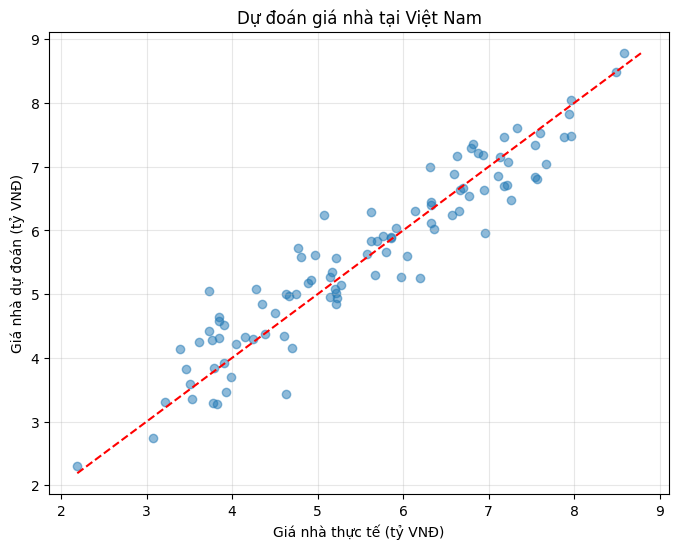

   Gia_thuc_te  Gia_du_doan
0         5.86        5.895
1         7.18        7.462
2         3.51        3.595
3         4.24        4.300
4         6.79        7.301
5         4.92        5.220
6         3.85        4.641
7         3.85        4.575
8         3.99        3.693
9         7.11        6.858


In [18]:

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
housing = pd.read_csv("vietnam_housing.csv")
X = housing.drop(columns=["Price"])
y = housing["Price"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LinearRegression()
)
model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("MAE:", round(mean_absolute_error(y_test, y_pred), 3), "tỷ VNĐ")
print("RMSE:", round(mean_squared_error(y_test, y_pred) ** 0.5, 3), "tỷ VNĐ")
print("R2:", round(r2_score(y_test, y_pred), 3))
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.5)
min_val = min(y_test.min(), y_pred.min())
max_val = max(y_test.max(), y_pred.max())
plt.plot(
    [min_val, max_val],
    [min_val, max_val],
    "r--"
)
plt.xlabel("Giá nhà thực tế (tỷ VNĐ)")
plt.ylabel("Giá nhà dự đoán (tỷ VNĐ)")
plt.title("Dự đoán giá nhà tại Việt Nam")
plt.grid(alpha=0.3)
plt.show()
ket_qua = pd.DataFrame({
    "Gia_thuc_te": y_test.iloc[:10].values,
    "Gia_du_doan": y_pred[:10]
})
print(ket_qua.round(3))
